# Medical Insurance - EDA

## 1. Importer les outils

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Mêmes couleurs partout : rouge = fumeur, bleu = non-fumeur
COULEURS = {"yes": "#E45756", "no": "#4C78A8"}

## 2. Charger les données

Change le chemin si ton fichier est ailleurs.

In [2]:
df = pd.read_csv("../data/raw/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Regarder les données

On regarde la taille, les types de colonnes et les statistiques de base.

In [3]:
print("Lignes :", df.shape[0])
print("Colonnes :", df.shape[1])
df.info()

Lignes : 1338
Colonnes : 7
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
df.describe().round(2)

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


- `charges` : la moyenne est plus haute que la médiane. Quelques gros coûts tirent la moyenne vers le haut.
- `age` va de 18 à 64 ans. `bmi` : 30 ou plus = obésité.

## 4. Qualité des données

Peut-on faire confiance aux données ?

In [5]:
print("Valeurs manquantes :")
print(df.isnull().sum())
print()
print("Lignes en double :", df.duplicated().sum())

Valeurs manquantes :
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Lignes en double : 1


## 5. Comment sont répartis les coûts ?

Tous les clients coûtent-ils pareil ?

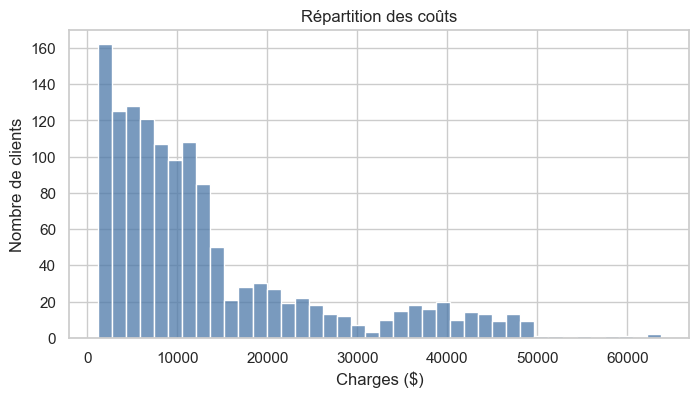

Moyenne : 13270 $
Médiane : 9382 $


In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(df["charges"], bins=40, color="#4C78A8")
plt.title("Répartition des coûts")
plt.xlabel("Charges ($)")
plt.ylabel("Nombre de clients")
plt.show()

print("Moyenne :", round(df["charges"].mean()), "$")
print("Médiane :", round(df["charges"].median()), "$")

## 6. Fumer change-t-il le coût ?

Oui, les fumeurs coûtent plus cher.

In [7]:
# Moyenne et médiane par statut
print(df.groupby("smoker")["charges"].agg(["count", "mean", "median"]).round(0))

# Part des clients et part des coûts
part_clients = df["smoker"].value_counts(normalize=True) * 100
part_couts = df.groupby("smoker")["charges"].sum() / df["charges"].sum() * 100
print()
print("Part des clients (%) :")
print(part_clients.round(1))
print("Part des coûts (%) :")
print(part_couts.round(1))

        count     mean   median
smoker                         
no       1064   8434.0   7345.0
yes       274  32050.0  34456.0

Part des clients (%) :
smoker
no     79.5
yes    20.5
Name: proportion, dtype: float64
Part des coûts (%) :
smoker
no     50.5
yes    49.5
Name: charges, dtype: float64


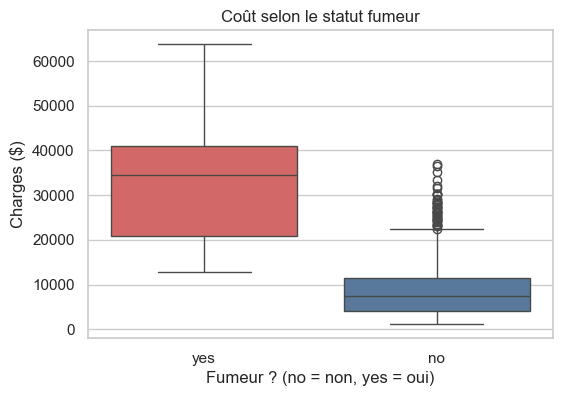

In [8]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="smoker", y="charges", hue="smoker", palette=COULEURS, legend=False)
plt.title("Coût selon le statut fumeur")
plt.xlabel("Fumeur ? (no = non, yes = oui)")
plt.ylabel("Charges ($)")
plt.show()

- Les fumeurs sont environ 20 % des clients, mais font près de la moitié du coût total.
- Un fumeur coûte en moyenne environ 4 fois plus cher qu'un non-fumeur.
- C'est le facteur n°1.

## 7. L'âge change-t-il le coût ?

Plus on vieillit, plus c'est cher.

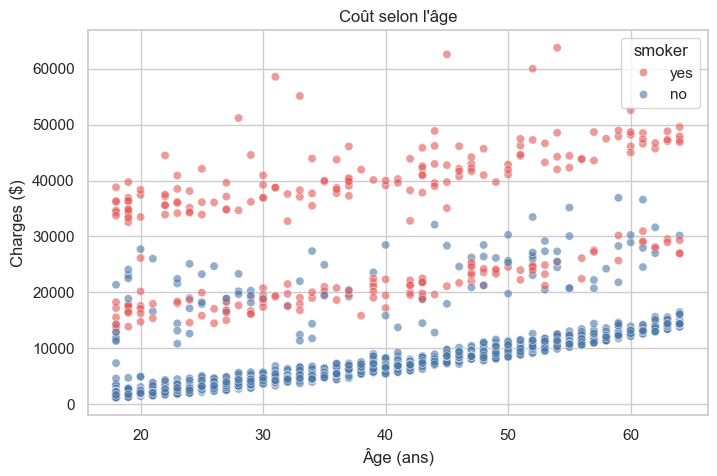

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", palette=COULEURS, alpha=0.6)
plt.title("Coût selon l'âge")
plt.xlabel("Âge (ans)")
plt.ylabel("Charges ($)")
plt.show()

Le coût monte avec l'âge. On voit aussi des bandes : la bande du haut est surtout faite de fumeurs.

## 8. Le BMI change-t-il le coût ?

Les personnes obèses (BMI de 30 ou plus) coûtent plus cher.

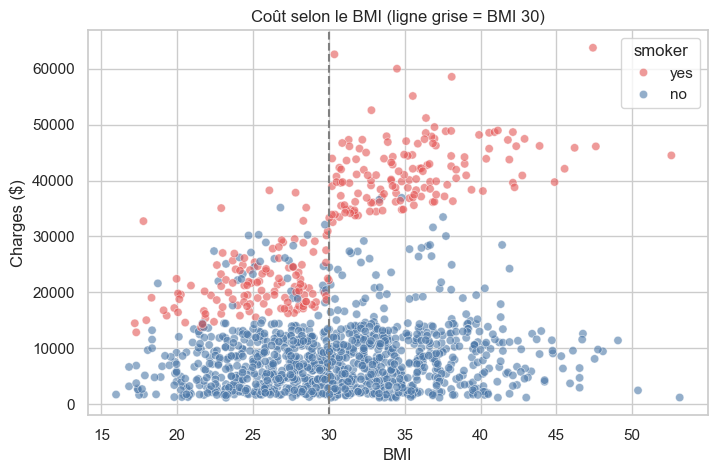

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", palette=COULEURS, alpha=0.6)
plt.axvline(30, color="gray", linestyle="--")
plt.title("Coût selon le BMI (ligne grise = BMI 30)")
plt.xlabel("BMI")
plt.ylabel("Charges ($)")
plt.show()

In [11]:
# Coût moyen : obèse ou non, fumeur ou non
df["obese"] = df["bmi"] >= 30
print(df.groupby(["smoker", "obese"])["charges"].mean().round(0))

smoker  obese
no      False     7977.0
        True      8843.0
yes     False    21363.0
        True     41558.0
Name: charges, dtype: float64


- Chez les **non-fumeurs**, le BMI change peu le coût.
- Chez les **fumeurs**, le coût monte fortement quand le BMI dépasse 30.
- Le BMI compte surtout quand on fume. On appelle ça une **interaction**. Il faudra en tenir compte dans le modèle.

## 9. Sexe, région et enfants

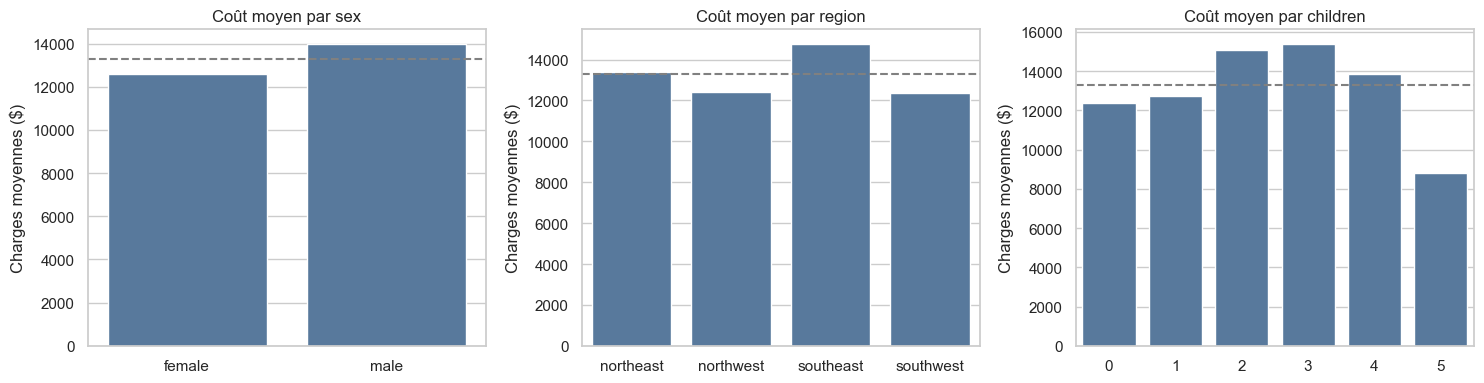

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["sex", "region", "children"]):
    moyennes = df.groupby(col)["charges"].mean()
    sns.barplot(x=moyennes.index, y=moyennes.values, color="#4C78A8", ax=ax)
    ax.axhline(df["charges"].mean(), color="gray", linestyle="--")
    ax.set_title("Coût moyen par " + col)
    ax.set_xlabel("")
    ax.set_ylabel("Charges moyennes ($)")

plt.tight_layout()
plt.show()

Les écarts sont petits. Une partie vient du tabac (par exemple, plus d'hommes fument). Ces variables comptent peu.

## 10. Corrélations

On transforme `smoker` et `sex` en 0/1 pour les mettre dans la matrice. Plus la valeur est proche de 1, plus le lien est fort avec `charges`.

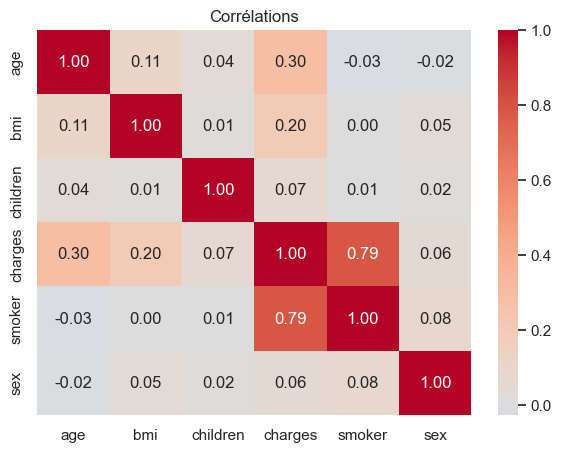

In [13]:
df_num = df[["age", "bmi", "children", "charges"]].copy()
df_num["smoker"] = (df["smoker"] == "yes").astype(int)
df_num["sex"] = (df["sex"] == "male").astype(int)

plt.figure(figsize=(7, 5))
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations")
plt.show()

- `smoker` a le lien le plus fort avec `charges`, puis `age`, puis `bmi`. `sex` et `children` sont presque à zéro.

- la corrélation ne voit que les liens en ligne droite. Elle ne montre pas l'interaction fumeur × BMI qu'on a vue plus haut.